# Module 02: Training Splits

### Load necessary packages

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from ISLP.models import summarize
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots

### Create helper functions for computing predictions and the mean squared error

In [2]:

def predict(X, model):
    '''
    The built-in "get_prediction" tool in ISLP returns an array, so this is just a wrapper which converts the result to a dataframe.
    '''
    predictions_df = pd.DataFrame(model.get_prediction(X).predicted, columns=['y_hat'], index=X.index)
    return predictions_df['y_hat']

def mse(y, y_hat):
    '''
    Returns the mean squared error, which we will use to evaluate how well a linear regression model fits a dataset.

    The details of this function will be explored further in module 04.
    '''
    # calculate the residual error for each individual record
    resid = y - y_hat
    # square the residual (hence "squared error")
    sq_resid = resid**2
    # calculate the sum of squared errors
    SSR = sum(sq_resid)
    # divide by the number of records to get the mean squared error
    MSE = SSR / y.shape[0]
    return MSE

### Randomly generate a dataset using the equation y = x - 2x^2

In [3]:

# Always specify a seed so that the data can be regenerated
# DON'T change anything in this cell.
seed = 314

# Create a random number generator called rng
rng = np.random.default_rng(seed)

# Use the random number generator to create x- and y-coordinates
x = rng.normal(size=150)
y = x - 2 * x**2 + rng.normal(size=150)

### Create a dataframe we can use to build three different models

In [4]:
# We'll need a collection of independent variables. We'll use x, x^2, x^3, and a constant (which will be used to calculate the intercept)
new_x = pd.DataFrame(np.column_stack((x**0, x, x**2, x**3)), columns=['intercept','x','x_sq','x_cu'])

# print the dataframe
new_x

     intercept         x          x_sq          x_cu
0          1.0 -0.623223  3.884072e-01 -2.420644e-01
1          1.0 -0.556297  3.094658e-01 -1.721548e-01
2          1.0  0.037388  1.397858e-03  5.226301e-05
3          1.0  0.995960  9.919372e-01  9.879302e-01
4          1.0  0.029919  8.951412e-04  2.678165e-05
5          1.0  0.348075  1.211559e-01  4.217131e-02
6          1.0  0.132315  1.750727e-02  2.316476e-03
7          1.0  0.151695  2.301137e-02  3.490709e-03
8          1.0 -0.148900  2.217118e-02 -3.301287e-03
9          1.0 -0.062405  3.894371e-03 -2.430279e-04
10         1.0 -1.834275  3.364563e+00 -6.171533e+00
11         1.0 -0.524987  2.756111e-01 -1.446922e-01
12         1.0  0.479866  2.302716e-01  1.104995e-01
13         1.0  1.225152  1.500997e+00  1.838949e+00
14         1.0  0.907079  8.227919e-01  7.463371e-01
15         1.0 -0.245031  6.004001e-02 -1.471164e-02
16         1.0  0.223027  4.974124e-02  1.109366e-02
17         1.0  1.141075  1.302053e+00  1.4857

### Split the data into train and test

In [5]:
# Note that we need to choose a random seed and the percent of records withheld for testing
x_train, x_test, y_train, y_test = train_test_split(new_x,
                                                    y,
                                                    random_state=314159,
                                                    test_size=0.33,
                                                    shuffle=True) 

### Graph the training data

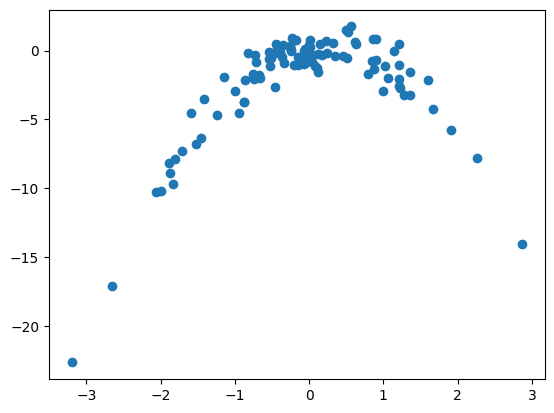

In [6]:
# It's important to do this after the train/test split is created. We shouldn't look at data that's withheld for testing.
fig, ax = plt.subplots()
ax.scatter(x_train['x'],y_train)

### First we'll a quadratic model, which should be appropriate since the data was randomly generated based on a quadratic equation

In [7]:
# Fit a quadratic model
model_quad = sm.OLS(y_train, x_train[['intercept','x','x_sq']])
results_quad = model_quad.fit()
summarize(results_quad)

             coef  std err       t  P>|t|
intercept  0.0943    0.114   0.830  0.408
x          0.9255    0.092  10.028  0.000
x_sq      -1.9932    0.056 -35.579  0.000

In [8]:
# Get predictions
x_train['pred_sq'] = predict(x_train[['intercept', 'x', 'x_sq']], results_quad)

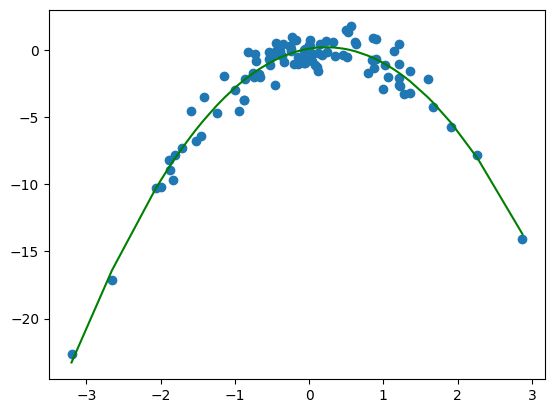

In [9]:
# Plot predictions as solid green line, along with the original training data
fig, ax = plt.subplots()
ax.scatter(x_train['x'],y_train)
quadratic = x_train[['x','pred_sq']].sort_values('x')
ax.plot(quadratic['x'],quadratic['pred_sq'], color='green')

### Next we'll create an underfit model and observe the performance on training.

In [10]:
# Fit a linear model
model_lin = sm.OLS(y_train, x_train[['intercept','x']])
results_lin = model_lin.fit()
summarize(results_lin)

             coef  std err      t  P>|t|
intercept -2.0760    0.358 -5.807    0.0
x          1.5604    0.338  4.621    0.0

In [11]:
# Get model predictions
x_train['pred_lin'] = predict(x_train[['intercept', 'x']], results_lin)

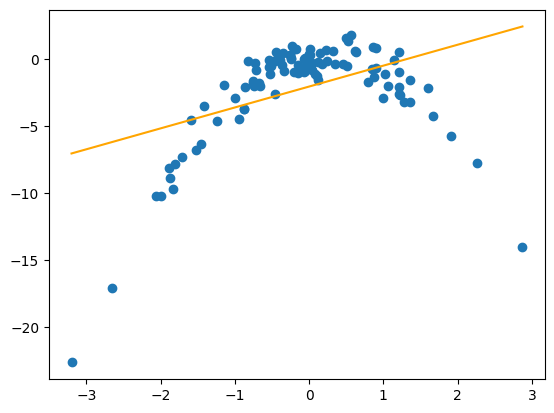

In [12]:
# Plot predictions as solid *orange* line
fig, ax = plt.subplots()
ax.scatter(x_train['x'],y_train)
linear = x_train[['x','pred_lin']].sort_values('x')
ax.plot(linear['x'], linear['pred_lin'], color='orange')

### And lastly we'll build an overfit model and observe the performance on training.

In [13]:
# Fit a cubic model
model_cubic = sm.OLS(y_train, x_train[['intercept','x','x_sq','x_cu']])
results_cubic = model_cubic.fit()
summarize(results_cubic)

             coef  std err       t  P>|t|
intercept  0.0992    0.115   0.861  0.391
x          0.9617    0.147   6.528  0.000
x_sq      -1.9984    0.059 -34.068  0.000
x_cu      -0.0099    0.031  -0.316  0.753

In [14]:
# Get predictions
x_train['pred_cu'] = predict(x_train[['intercept', 'x', 'x_sq', 'x_cu']], results_cubic)

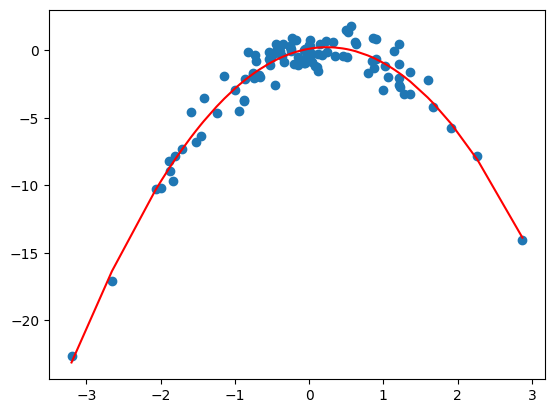

In [15]:
# Plot predictions as solid *red* line
fig, ax = plt.subplots()
ax.scatter(x_train['x'],y_train)
cubic = x_train[['x','pred_cu']].sort_values('x')
ax.plot(cubic['x'], cubic['pred_cu'], color='red')

### After observing the resulting three plots on the training set, how do the models compare? Is one clearly the best? Is one clearly the worst?

On the training plots, the linear (orange) model is clearly the worst. The scatter follows a curved, downward-opening pattern, and a straight line cannot capture that shape, so many points sit far from the line.

The quadratic (green) and cubic (red) curves both follow the training points closely, so neither is obviously better from the plots alone. The cubic curve can bend a little more at the edges, but the two fits look similar in the bulk of the data. Because the data were generated from a quadratic equation, the quadratic model is the one we expect to be appropriate; the training plots by themselves do not prove that yet.

### Now we'll calculate the errors (MSE) for each model on the training and test sets.

In [16]:
# Calculate the MSE on the training set for each model
predictions_lin_train = predict(x_train[['intercept', 'x']], results_lin)
predictions_quad_train = predict(x_train[['intercept', 'x', 'x_sq']], results_quad)
predictions_cubic_train = predict(x_train[['intercept', 'x', 'x_sq', 'x_cu']], results_cubic)

print('mse train linear   :',mse(y_train, predictions_lin_train))
print('mse train quadratic:',mse(y_train, predictions_quad_train))
print('mse train cubic    :',mse(y_train, predictions_cubic_train))

mse train linear   : 12.41296628882376
mse train quadratic: 0.8834818567246728
mse train cubic    : 0.8825659366137271


In [17]:
# Calculate the MSE on the test set for each model
predictions_lin_test = predict(x_test[['intercept', 'x']], results_lin)
predictions_quad_test = predict(x_test[['intercept', 'x', 'x_sq']], results_quad)
predictions_cubic_test = predict(x_test[['intercept', 'x', 'x_sq', 'x_cu']], results_cubic)

print('mse test linear   :',mse(y_test, predictions_lin_test))
print('mse test quadratic:',mse(y_test, predictions_quad_test))
print('mse test cubic    :',mse(y_test, predictions_cubic_test))

mse test linear   : 4.384456331794726
mse test quadratic: 1.1722830126932597
mse test cubic    : 1.1747427656171412


### Describe the results for each of the three models in terms of their performance on training data and on test data. Which model is most likely underfit? Which is most likely overfit?

The linear model has the highest MSE on both sets (about 12.41 on training and 4.38 on test), so it is underfit: a straight line is too simple for the true quadratic relationship.

The cubic model has the lowest training MSE (about 0.883, slightly below the quadratic model) but a higher test MSE than the quadratic model (about 1.175 vs 1.172). That pattern is overfitting: the extra \(x^3\) term fits a little training noise that does not help on new data.

The quadratic model has low training error (about 0.883) and the lowest test error (about 1.172). It is the best of the three, which matches how the data were generated.